## A/B Testing, Randomized Controlled Trials

Lukas Vrouwenvelder


- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [114]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [115]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


#### Response

No, not by these metrics. ATE is slightly negative, so the conservative survival rate was slightly larger than the invasive (Balloon), so I'd rather not get the invasive balloon procedure. It is invasive (which is likely an unplesant process as a whole), and less effective based on proportion of successes. 

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [116]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

#### Response

Generally, we see that the KDEs overlap substantially. Conservative treatment (no balloon) has a slightly higher observed survival rate than the invasive (balloon) approach, the KDEs overlap over most of their range. At every cumulative proportion, the conservative ECDF lies to the right (higher survival rate, magnitude visualized by the horizontal gap b/w invasive and conservative interventions). 

Similarly, in the bootstrapped KDE, the peak density is roughly .01 further right (higher survival rate) in conservative interventions than in invasive interventions. The KDEs are visually similar in width and height, but the conservative KDE is shifted right at all points.

Both appear approximately normal (CLT), and smooth from the 10,000 replicates.

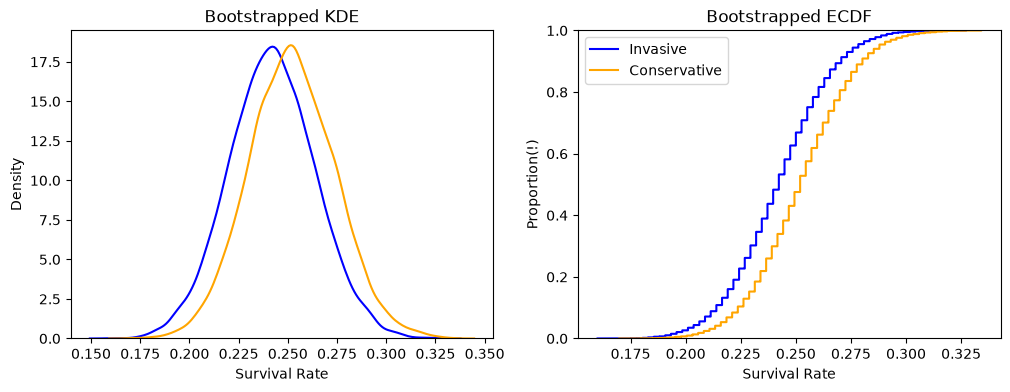

In [117]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Proportion(!)')

plt.legend()
plt.show()

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

#### Response

The bootstrapped KDE for ATE is roughly bell shaped. The possible results from this intervention range from roughly -.11 to +.10 over the 10,000 bootstrap draws. The peak density of the bootstrapped KDE for ATE appears to sit just below 0.0, indicating that more than half of the resamples, the ATE came out to be negative. This is consistent with a true effect somewhere near 0. 

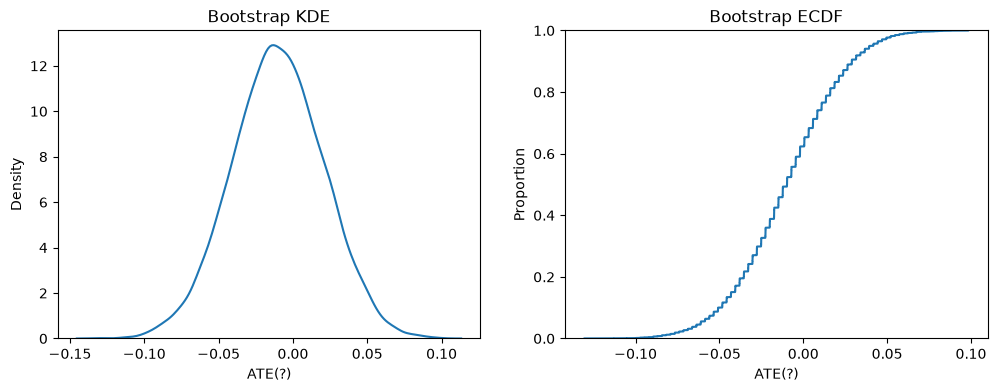

In [118]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
# ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_xlabel("ATE(?)")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
# ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_xlabel("ATE(?)")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

#### Response

Yes, 0 is in all of the confidence intervals, meaning that we fail to reject the null hypothesis at all 3 significance levels (alpha = .1, .05, and .01). We fail to reject the hypothesis that ATE = 0 between outcomes for patients in invasive treatment and conservative treatment groups.

In [119]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06113349  0.03947473]
95% CI: [-0.07142289  0.04955212]
99% CI: [-0.08949726  0.06759342]


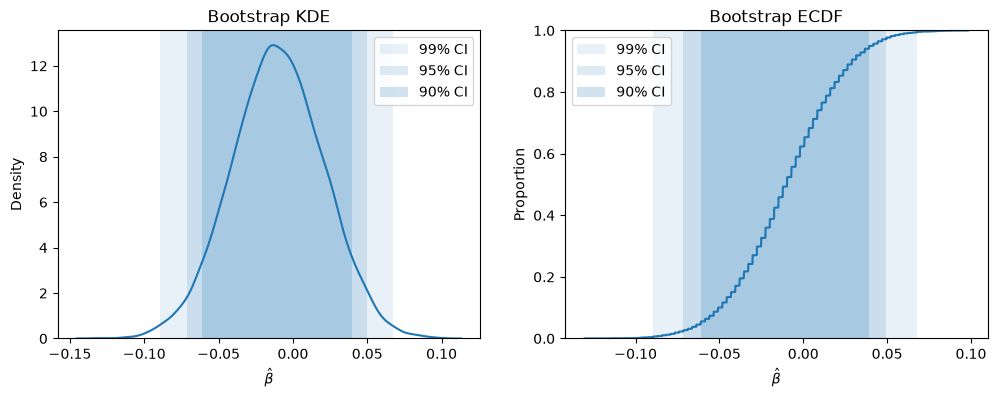

In [120]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

#### Response

We have learned that there is no evidence here to support the conclusion that this is an effective procedure judging by the average treatment effect. There is no statistically significant difference between invasive (balloon) and conservative approaches. Although statistically insignificant, intra-aortic balloon pump patients seem to fare more poorly.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

---
## Part 2: Diabetes trial (three arms)

**1.** Crosstab and average outcomes

In [121]:
dm = pd.read_csv('./data/diabetes.csv', index_col=0)      # first column is just a row id
dm['y'] = (dm['outcome'] == 'success').astype(int)          # 1 = success, 0 = failure

print(pd.crosstab(dm['treatment'], dm['outcome'], margins=True), '\n')

arm_summary = dm.groupby('treatment')['y'].agg(n='size', successes='sum', success_rate='mean')
arm_summary.round(4)

outcome    failure  success  All
treatment                       
lifestyle      109      125  234
met            120      112  232
rosi            90      143  233
All            319      380  699 



,n,successes,success_rate
treatment,,,
lifestyle,234,125,0.5342
met,232,112,0.4828
rosi,233,143,0.6137


#### Response
In order of highest to lowest average success rates, the treatments are:
- Rosiglitazone, with an average success rate of 61%
- Lifestyle, with an average success rate of 53%
- Metformin, with an average success rate of 48%



**2.** Bootstrap the three arms, resampling within each arm

In [122]:
# claude assisted code 
R = 10_000
rng = np.random.default_rng(5030)                             # fixed seed -> reproducible

arms = ['met', 'rosi', 'lifestyle']
arm_y = {g: dm.loc[dm['treatment'] == g, 'y'].to_numpy() for g in arms}   # 0/1 outcomes for each arm

boot = {g: np.empty(R) for g in arms}
for t in range(R):
    for g in arms:
        y = arm_y[g]
        boot[g][t] = rng.choice(y, size=len(y), replace=True).mean()       # same size as the arm, with replacement

boot = pd.DataFrame(boot)          # R rows x 3 arms: each row is one simulated trial
boot.describe().T[['mean', 'std', 'min', 'max']].round(4)

,mean,std,min,max
met,0.4827,0.0328,0.3319,0.6164
rosi,0.6141,0.0318,0.4893,0.7167
lifestyle,0.5342,0.0327,0.4017,0.6752


In [123]:
# Sanity check: the bootstrap SD should be close to the SE of a proportion, sqrt(p(1 - p) / n)
p, n = arm_summary.loc[arms, 'success_rate'], arm_summary.loc[arms, 'n']
pd.DataFrame({'bootstrap SD': boot.std(), 'formula SE': np.sqrt(p * (1 - p) / n)}).round(4)

,bootstrap SD,formula SE
met,0.0328,0.0328
rosi,0.0318,0.0319
lifestyle,0.0327,0.0326


**3.** Densities and distributions of the three arms

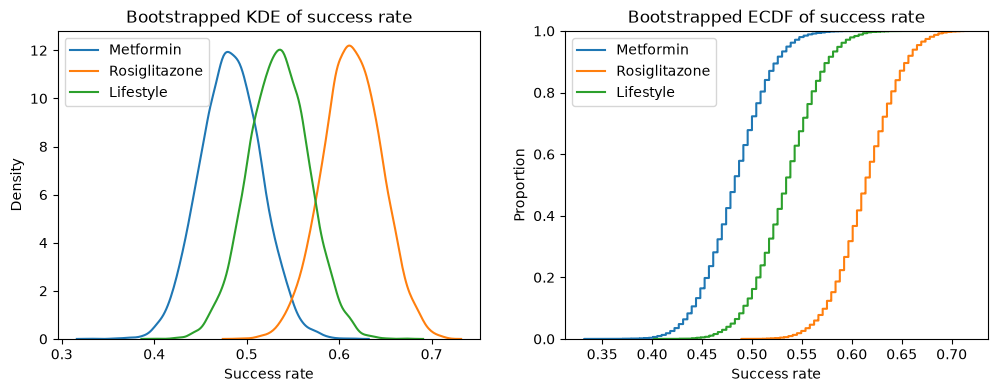

In [124]:
# claude assisted code 
colors = {'met': 'tab:blue', 'rosi': 'tab:orange', 'lifestyle': 'tab:green'}
labels = {'met': 'Metformin', 'rosi': 'Rosiglitazone', 'lifestyle': 'Lifestyle'}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for g in arms:
    sns.kdeplot(boot[g], label=labels[g], color=colors[g], ax=ax[0])
    sns.ecdfplot(boot[g], label=labels[g], color=colors[g], ax=ax[1])
ax[0].set(title='Bootstrapped KDE of success rate', xlabel='Success rate', ylabel='Density')
ax[1].set(title='Bootstrapped ECDF of success rate', xlabel='Success rate', ylabel='Proportion')
ax[0].legend()
ax[1].legend()
plt.show()

#### Response

Distributions of success rate are of nearly identical height and width across all three treatments. The bootstrapping backs our previous reporting on success rates; rosiglitazone demonstrates the highest success rate across the entire distribution. It's ECDF is shifted right (towards higher success rates) at all proportions. Because the KDE is a smoothed version of the ECDF's slope, and the three bootstrap distributions have nearly the same spread, the rightward shift in rosiglitazone's ECDF appears as the same rightward shift in its KDE. Its highest density is just above .6, which agrees with previous findings. 

Moving left, we see lifestyle reporting the next highest success rates. It is shifted right of Metformin, but by a visually smaller margin than rosiglitazone is shifted from lifestyle. The KDE for lifestyle peaks close to .53, which is the same as the .53 we found pre-bootstrap. Any difference observed here would be attributed to Monte Carlo noise from using a finite R. When R=10,000, these figures agree closely. 

The leftmost plot is Metformin, showing lower success rates at all proportions in the ECDF. It's peak density (mean) is close to .48, again matching our calculation of .48 in our first investigation.

**4.** The three pairwise treatment effects

In [125]:
# claude assisted code 
comparisons = {'met − rosi': ('met', 'rosi'),
               'met − lifestyle': ('met', 'lifestyle'),
               'rosi − lifestyle': ('rosi', 'lifestyle')}

ate = pd.DataFrame({name: boot[a] - boot[b] for name, (a, b) in comparisons.items()})
ate_hat = pd.Series({name: arm_summary.loc[a, 'success_rate'] - arm_summary.loc[b, 'success_rate']
                     for name, (a, b) in comparisons.items()}, name='point estimate')
ate_hat.round(4)

met − rosi         -0.1310
met − lifestyle    -0.0514
rosi − lifestyle    0.0795
Name: point estimate, dtype: float64

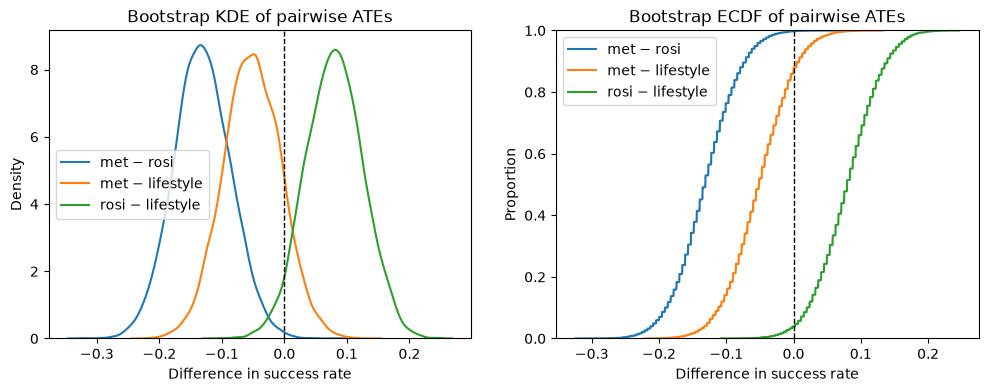

In [126]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in ate:
    sns.kdeplot(ate[name], label=name, ax=ax[0])
    sns.ecdfplot(ate[name], label=name, ax=ax[1])
for a in ax:
    a.axvline(0, color='black', ls='--', lw=1)       # 0 = no difference between the two arms
    a.legend()
ax[0].set(title='Bootstrap KDE of pairwise ATEs', xlabel='Difference in success rate', ylabel='Density')
ax[1].set(title='Bootstrap ECDF of pairwise ATEs', xlabel='Difference in success rate', ylabel='Proportion')
plt.show()

**5.** Percentile bootstrap confidence intervals for each pairwise ATE

In [127]:
# claude assisted code 
levels = {'90%': 0.10, '95%': 0.05, '99%': 0.01}
rows = []
for name in ate:
    row = {'comparison': name, 'estimate': round(ate_hat[name], 4)}
    for lab, a in levels.items():
        lo, hi = np.quantile(ate[name], [a / 2, 1 - a / 2])
        row[f'{lab} CI'] = f'[{lo:.3f}, {hi:.3f}]'
        row[f'0 in {lab}?'] = lo <= 0 <= hi
    rows.append(row)
ci_table = pd.DataFrame(rows).set_index('comparison')
ci_table

,estimate,90% CI,0 in 90%?,95% CI,0 in 95%?,99% CI,0 in 99%?
comparison,,,,,,,
met − rosi,-0.1310,"[-0.204, -0.054]",False,"[-0.221, -0.041]",False,"[-0.247, -0.011]",False
met − lifestyle,-0.0514,"[-0.128, 0.026]",True,"[-0.141, 0.039]",True,"[-0.172, 0.069]",True
rosi − lifestyle,0.0795,"[0.007, 0.157]",False,"[-0.010, 0.169]",True,"[-0.036, 0.195]",True


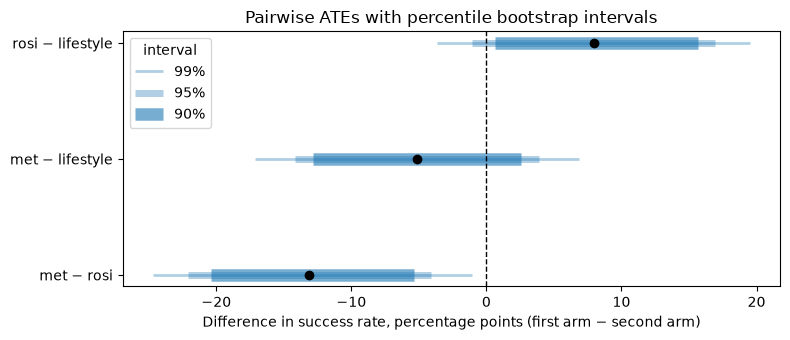

In [128]:
# claude assisted code 
def forest_plot(ate, ate_hat, title='Pairwise ATEs with percentile bootstrap intervals', pp=True):
    """Build the forest plot and RETURN the Figure (it does not draw it), so it can be shown in any cell."""
    k = 100 if pp else 1
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for i, name in enumerate(ate.columns):
        for lab, a, lw in [('99%', 0.01, 2), ('95%', 0.05, 5), ('90%', 0.10, 9)]:
            lo, hi = np.quantile(ate[name], [a / 2, 1 - a / 2])
            ax.plot([k * lo, k * hi], [i, i], lw=lw, color='tab:blue', alpha=0.6 if lab == '90%' else 0.35,
                    solid_capstyle='butt', label=lab if i == 0 else None)
        ax.plot(k * ate_hat[name], i, 'o', color='black', zorder=3)
    ax.axvline(0, color='black', ls='--', lw=1)
    ax.set_yticks(range(len(ate.columns)), ate.columns)
    unit = 'percentage points' if pp else 'proportion'
    ax.set(xlabel=f'Difference in success rate, {unit} (first arm − second arm)', title=title)
    ax.legend(title='interval', loc='upper left')
    fig.tight_layout()
    plt.close(fig)          # stops Jupyter from auto-drawing it here; we choose where it appears
    return fig

fig_forest = forest_plot(ate, ate_hat)
fig_forest                  # last line of a cell -> the figure renders here

#### Response

The difference between metformin and rosiglitazone is statistically significant at all confidence intervals listed (CI =90%, 95%, 99%). This is evidenced by the lack of overlap with 0.0 (none of the CIs contain 0). Formally, we can say that none of the 3 confidence intervals at the given significance levels include 0, so we reject the null hypothesis that there is no real difference between metformin and rosiglitazone outcomes.

Depending on where we set our alpha, there is a statistically significant difference between rosiglitazone and lifestyle interventions. When alpha =.1, we can reject the null. however, when alpha =.05, .01, we fail to reject the null. At those corresponding confidence intervals, 0 falls within the range of the interval, and we can not definitively say that there is a significant difference in ATE between those two interventions.

Based on these confidence intervals, and the ECDFs and KDEs from our bootstrapping simulations, rosiglitazone appears to be a more effective intervention than metformin, and potentially better than lifestyle. Rosiglitazone shows a higher success rate at any given proportion of bootstrap replicates, and is a better drug than metformin by ATE, and is a better intervention than lifestyle at the 90% confidence level.

Metformin vs. lifestyle contains 0 at every level. 

**6.** Report

In [129]:
# claude assisted code 
order = arm_summary.index                                   # keep boot columns aligned with arm_summary rows
arm_table = arm_summary.copy()
arm_table['95% CI'] = [f'[{lo:.3f}, {hi:.3f}]'
                       for lo, hi in zip(boot[order].quantile(0.025), boot[order].quantile(0.975))]
arm_table.index = arm_table.index.map(labels)
display(arm_table.round(3))

effect_table = pd.DataFrame({
    'estimate (pp)': (100 * ate_hat).round(1),
    '90% CI (pp)': [f'[{100 * lo:.1f}, {100 * hi:.1f}]' for lo, hi in zip(ate.quantile(0.05), ate.quantile(0.95))],
    '95% CI (pp)': [f'[{100 * lo:.1f}, {100 * hi:.1f}]' for lo, hi in zip(ate.quantile(0.025), ate.quantile(0.975))],
    '99% CI (pp)': [f'[{100 * lo:.1f}, {100 * hi:.1f}]' for lo, hi in zip(ate.quantile(0.005), ate.quantile(0.995))],

    'NNT': (1 / ate_hat.abs()).round(1),        # patients treated per one extra success
})
display(effect_table)

,n,successes,success_rate,95% CI
treatment,,,,
Lifestyle,234,125,0.534,"[0.470, 0.598]"
Metformin,232,112,0.483,"[0.418, 0.547]"
Rosiglitazone,233,143,0.614,"[0.549, 0.678]"


,estimate (pp),90% CI (pp),95% CI (pp),99% CI (pp),NNT
met − rosi,-13.1,"[-20.4, -5.4]","[-22.1, -4.1]","[-24.7, -1.1]",7.6
met − lifestyle,-5.1,"[-12.8, 2.6]","[-14.1, 3.9]","[-17.2, 6.9]",19.4
rosi − lifestyle,8.0,"[0.7, 15.7]","[-1.0, 16.9]","[-3.6, 19.5]",12.6


---
---

## Report

**Review of a randomized trial of metformin, rosiglitazone, and lifestyle adjustment for pre-diabetes**

This report reviews a randomized controlled trial comparing three interventions intended to slow the progression of pre-diabetes to full diabetes. Interventions include drugs metformin, and rosiglitazone, and lifestyle adjustment (diet and exercise). The trial randomized 699 patients into three arms of nearly equal size (232 metformin, 233 rosiglitazone, 234 lifestyle). Each patient's outcome is recorded as a binary success or failure. A success is read as the patient not progressing to diabetes during the trial. Because treatment was randomly assigned, differences in success rates between arms can be attributed to the interventions rather than to systematic differences between the patients in each arm.

We estimated each arm's success rate and the three pairwise average treatment effects (ATEs), each defined as the difference in success rates between two arms. To quantify sampling uncertainty, we drew 10,000 bootstrap samples, resampling patients with replacement within each arm so that each simulated trial keeps the original arm sizes and patient pool. Within each bootstrap, we recomputed the three success rates and their pairwise differences, and formed percentile confidence intervals at the 90%, 95%, and 99% levels (alpha = 0.10, 0.05, 0.01). For each comparison the null hypothesis is that the ATE equals 0.  We reject the null at a given alpha when the corresponding confidence interval excludes zero.

Rosiglitazone had the highest success rate, 61.4% (95% CI in the table 1 below), followed by lifestyle adjustment at 53.4% (table 1) and metformin at 48.3% (table 1). The bootstrap distributions of the three rates have nearly identical spread and are approximately normal, with mean, median, and mode approximately equal, as expected for an average of roughly 233 binary outcomes under the central limit theorem. The arm distributions overlap substantially, but we rely on the the intervals for the pairwise differences for more robust analysis.

**Table 1.** Success rate by arm, with 95% percentile bootstrap intervals.

In [130]:
display(arm_table)

,n,successes,success_rate,95% CI
treatment,,,,
Lifestyle,234,125,0.534188,"[0.470, 0.598]"
Metformin,232,112,0.482759,"[0.418, 0.547]"
Rosiglitazone,233,143,0.613734,"[0.549, 0.678]"


Table 2 and Figure 1 report the three pairwise effects, written as first arm minus second arm. A negative value means the second arm had the higher success rate. Metformin's success rate was 13.1 percentage points lower than rosiglitazone's (95% CI table 2). This interval excludes zero at all three levels, including 99% (table 2), so we reject the null hypothesis at alpha = 0.01. If the true difference were zero, a difference this large would occur in fewer than 1% of samples. Rosiglitazone's rate was 8.0 points higher than the lifestyle adjustment, but this difference is significant only at the 90% level (0.7 to 15.7). Its 95% interval includes zero, so under the null a difference this large would arise by chance less than 10% but more than 5% of the time, and we fail to reject at alpha = 0.05 and 0.01. Metformin's rate was 5.1 points lower than lifestyle adjustment's. The confidence interval includes zero at every level, so we fail to reject the null for this comparison.

**Table 2.** Pairwise treatment effects in percentage points (first arm − second arm), with 90%, 95%, and 99% percentile bootstrap intervals and the number needed to treat (NNT = 1 / |ATE|).

In [131]:
display(effect_table)

,estimate (pp),90% CI (pp),95% CI (pp),99% CI (pp),NNT
met − rosi,-13.1,"[-20.4, -5.4]","[-22.1, -4.1]","[-24.7, -1.1]",7.6
met − lifestyle,-5.1,"[-12.8, 2.6]","[-14.1, 3.9]","[-17.2, 6.9]",19.4
rosi − lifestyle,8.0,"[0.7, 15.7]","[-1.0, 16.9]","[-3.6, 19.5]",12.6


**Figure 1.** Pairwise treatment effects with 90% (thick), 95% (medium), and 99% (thin) percentile bootstrap intervals. The dashed line marks zero (no difference).

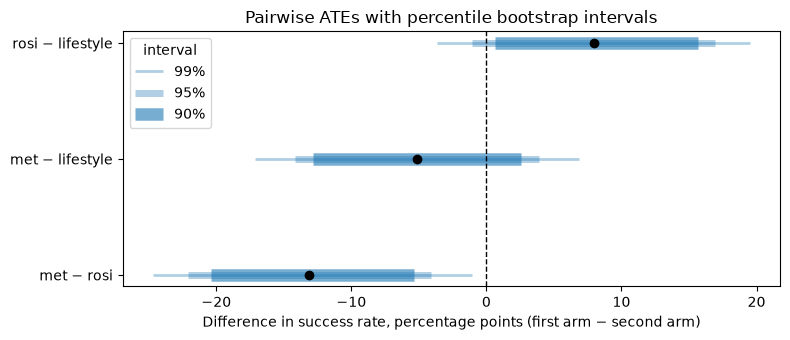

In [132]:
display(fig_forest)

The evidence supports rosiglitazone over metformin. The difference is significant at every level tested, and no CI includes 0 (fig 1). In practical terms, roughly 8 patients would need to receive rosiglitazone instead of metformin to produce one additional success (NNT 7.6, table 2). The evidence that rosiglitazone outperforms lifestyle adjustment is weak. The difference is significant only at the 90% level. No significant difference was detected that lifestyle adjustment and metformin differ. On efficacy alone (ignoring of side effects, drug cost, or other factors), rosiglitazone an effective intervention in this trial relative to metformin at the 99% confidence interval, and is effective relative to lifestyle adjustment at the 90% confidence interval only. Metformin and lifestyle adjustments are statistically indistinguishable from each other at any confidence level tested.

Based on these evidence, rosiglitazone is the best of the 3 treatment options. 